In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

df = pd.read_csv("../data/sample_dataset.csv")

print(df.head())
print(df.columns.tolist())

              Time   BS     Energy      load  ESMODE   TXpower
0  20230101 010000  B_0  64.275037  0.487936     0.0  7.101719
1  20230101 020000  B_0  55.904335  0.344468     0.0  7.101719
2  20230101 030000  B_0  57.698057  0.193766     0.0  7.101719
3  20230101 040000  B_0  55.156951  0.222383     0.0  7.101719
4  20230101 050000  B_0  56.053812  0.175436     0.0  7.101719
['Time', 'BS', 'Energy', 'load', 'ESMODE', 'TXpower']


In [4]:
X = df[["load"]]
y = df["Energy"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("AI training complete!")
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))

AI training complete!
Mean Absolute Error: 8.868726808171596


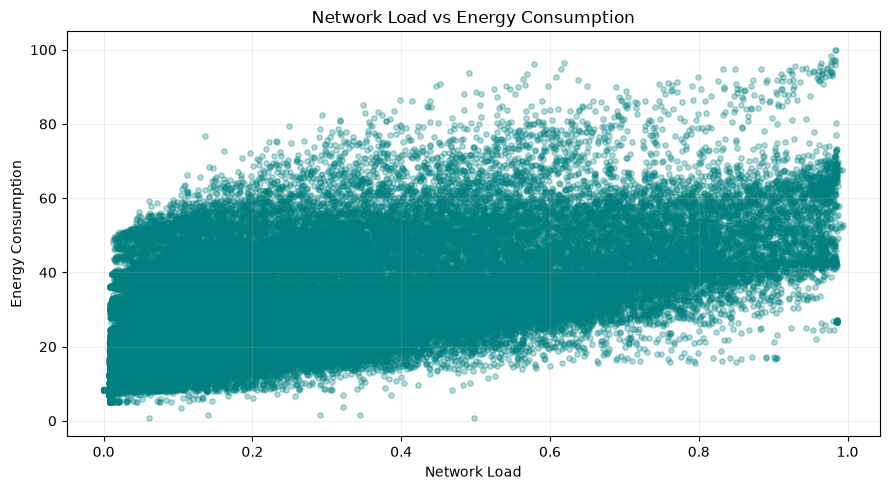

In [5]:

plt.figure(figsize=(9, 5))

plt.scatter(
    df["load"],
    df["Energy"],
    alpha=0.3,
    color="teal",
    s=15
)

plt.title("Network Load vs Energy Consumption")
plt.xlabel("Network Load")
plt.ylabel("Energy Consumption")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


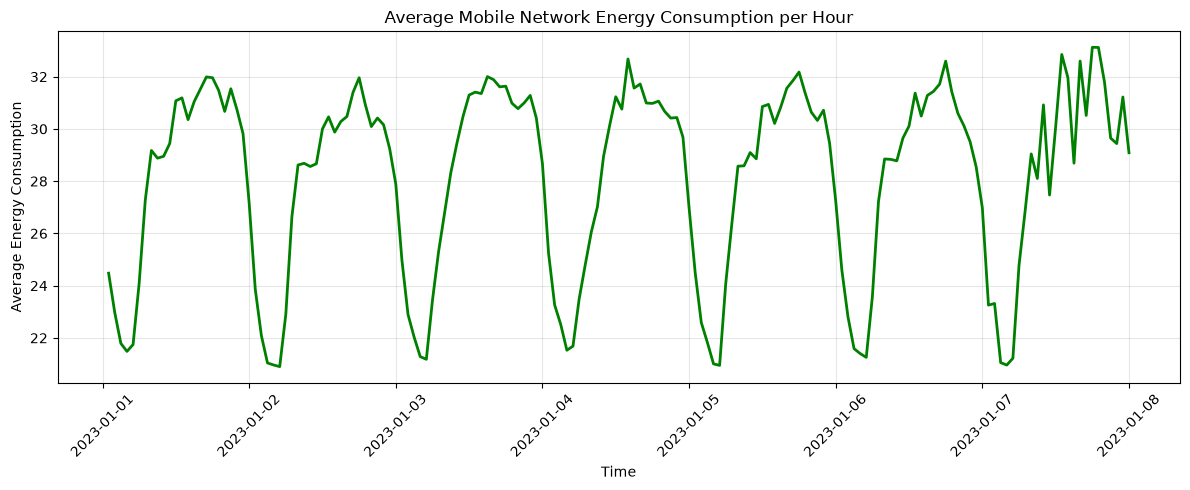

In [6]:
# Convert timestamps to datetime
df["parsed_time"] = pd.to_datetime(df["Time"], errors="coerce")

# Remove rows with invalid timestamps
time_data = df.dropna(subset=["parsed_time"]).copy()

# Group readings into hourly averages
time_data = time_data.set_index("parsed_time").sort_index()

hourly_energy = time_data["Energy"].resample("h").mean().dropna()

# Plot a clean line graph
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_energy.index,
    hourly_energy.values,
    color="green",
    linewidth=2
)

plt.title("Average Mobile Network Energy Consumption per Hour")
plt.xlabel("Time")
plt.ylabel("Average Energy Consumption")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

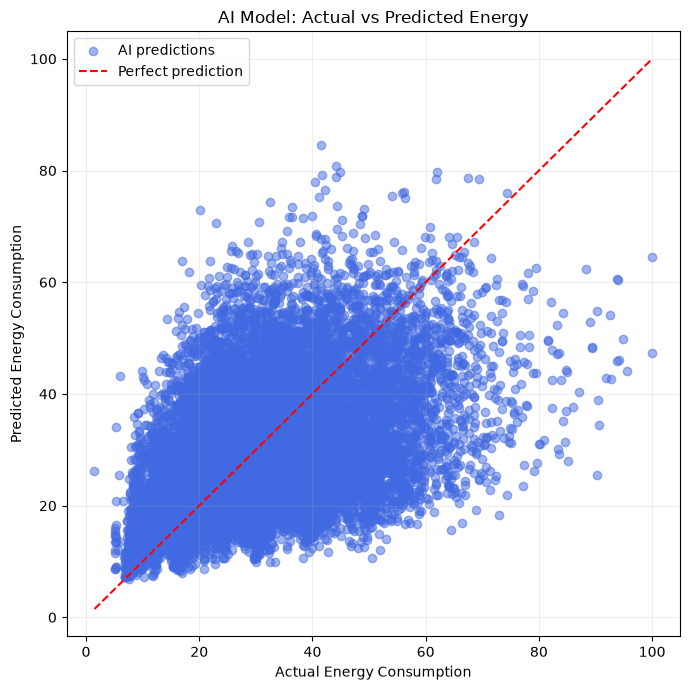

In [7]:

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    predictions,
    alpha=0.5,
    color="royalblue",
    label="AI predictions"
)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Energy Consumption")
plt.ylabel("Predicted Energy Consumption")
plt.title("AI Model: Actual vs Predicted Energy")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


<Figure size 800x500 with 0 Axes>

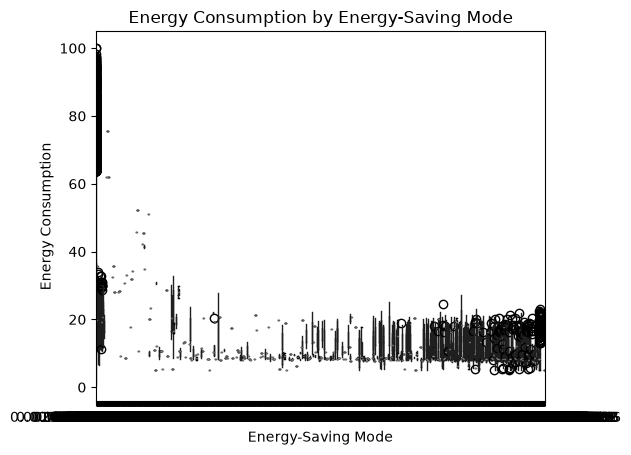

In [8]:

mode_col = next(
    (c for c in df.columns if c.lower() == "esmode"),
    None
)

if mode_col:
    plt.figure(figsize=(8, 5))

    df.boxplot(
        column="Energy",
        by=mode_col,
        grid=False
    )

    plt.title("Energy Consumption by Energy-Saving Mode")
    plt.suptitle("")
    plt.xlabel("Energy-Saving Mode")
    plt.ylabel("Energy Consumption")
    plt.tight_layout()
    plt.show()
else:
    print("No energy-saving mode column found.")


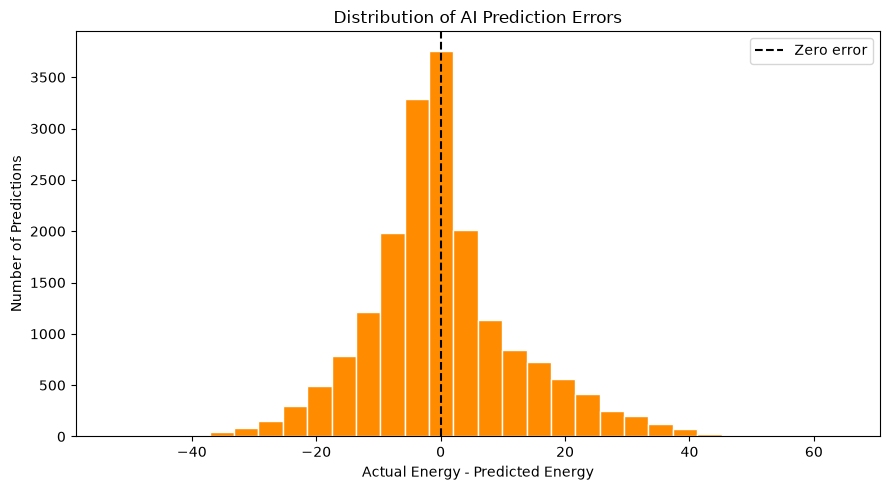

In [9]:

errors = np.asarray(y_test) - np.asarray(predictions)

plt.figure(figsize=(9, 5))

plt.hist(
    errors,
    bins=30,
    color="darkorange",
    edgecolor="white"
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    label="Zero error"
)

plt.title("Distribution of AI Prediction Errors")
plt.xlabel("Actual Energy - Predicted Energy")
plt.ylabel("Number of Predictions")
plt.legend()
plt.tight_layout()
plt.show()
